In [2]:
import glob, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

# Find our uploaded tiles wherever Kaggle mounted the dataset
paths = {s: glob.glob(f"/kaggle/input/**/{s}.npz", recursive=True)[0] for s in ["train", "val", "test"]}
data = {s: np.load(p) for s, p in paths.items()}
for s, d in data.items():
    print(s, d["X"].shape, d["y"].shape)

device: cuda Tesla T4
train (332, 4, 256, 256) (332, 256, 256)
val (41, 4, 256, 256) (41, 256, 256)
test (68, 4, 256, 256) (68, 256, 256)


Cell 2: prepare the inputs (scale the bands, add NDVI)

In [3]:
def to_features(X):
    X = X.astype("float32") / 10000.0                      # reflectance 0..1
    red, nir = X[:, 2], X[:, 3]
    ndvi = (nir - red) / (nir + red + 1e-6)
    return np.concatenate([X, ndvi[:, None]], axis=1)      # N x 5 x 256 x 256

feats = {s: to_features(d["X"]) for s, d in data.items()}
labels = {s: d["y"] for s, d in data.items()}

valid_train = labels["train"] != 255
mean = np.array([feats["train"][:, c][valid_train].mean() for c in range(5)], dtype="float32")
std = np.array([feats["train"][:, c][valid_train].std() for c in range(5)], dtype="float32")
for s in feats:
    feats[s] = (feats[s] - mean[None, :, None, None]) / std[None, :, None, None]
print("channel means:", mean.round(3), "stds:", std.round(3))
print("train features:", feats["train"].shape)

channel means: [0.049 0.074 0.085 0.265 0.529] stds: [0.022 0.029 0.05  0.048 0.24 ]
train features: (332, 5, 256, 256)


Cell 3: Dataset class with augmentation

In [4]:
class Tiles(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x, y = self.X[i], self.y[i]
        if self.augment:
            k = np.random.randint(4)                         # rotate 0/90/180/270
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
            if np.random.rand() < 0.5:                       # mirror
                x, y = x[:, :, ::-1], y[:, ::-1]
            scale = np.random.uniform(0.9, 1.1, size=(len(x), 1, 1)).astype("float32")
            shift = np.random.normal(0, 0.15, size=(len(x), 1, 1)).astype("float32")
            x = x * scale + shift                            # brightness jitter (standardised units)
        return torch.from_numpy(x.copy()), torch.from_numpy(y.copy()).long()

loaders = {
    "train": DataLoader(Tiles(feats["train"], labels["train"], augment=True), batch_size=16, shuffle=True, num_workers=2),
    "val": DataLoader(Tiles(feats["val"], labels["val"]), batch_size=16),
    "test": DataLoader(Tiles(feats["test"], labels["test"]), batch_size=16),
}

x, y = next(iter(loaders["train"]))
print("one batch ->", "x:", tuple(x.shape), x.dtype, "| y:", tuple(y.shape), y.dtype)
print("label values in batch:", torch.unique(y).tolist())

one batch -> x: (16, 5, 256, 256) torch.float32 | y: (16, 256, 256) torch.int64
label values in batch: [0, 1, 255]


Cell 4: the U-Net (the main part)

In [5]:
class ConvBlock(nn.Sequential):
    """Two 3x3 convolutions, each followed by batch norm and ReLU."""
    def __init__(self, c_in, c_out):
        super().__init__(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        )

class UNet(nn.Module):
    def __init__(self, in_ch=5, widths=(32, 64, 128, 256, 512)):
        super().__init__()
        self.down = nn.ModuleList()
        c = in_ch
        for w in widths:
            self.down.append(ConvBlock(c, w)); c = w
        self.up, self.dec = nn.ModuleList(), nn.ModuleList()
        for w in reversed(widths[:-1]):
            self.up.append(nn.ConvTranspose2d(c, w, 2, stride=2))   # double the size
            self.dec.append(ConvBlock(w * 2, w)); c = w            # *2: skip is concatenated
        self.head = nn.Conv2d(c, 1, 1)                             # 1 channel = forest score

    def forward(self, x):
        skips = []
        for i, block in enumerate(self.down):
            x = block(x)
            if i < len(self.down) - 1:
                skips.append(x)
                x = F.max_pool2d(x, 2)                             # halve the size
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), skip], dim=1))
        return self.head(x).squeeze(1)                             # logits, N x 256 x 256

model = UNet().to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

# trace one batch through the network to see the U shape
with torch.no_grad():
    t = x[:2].to(device)
    print("input          ", tuple(t.shape))
    for i, block in enumerate(model.down):
        t = block(t); print(f"down level {i}   ", tuple(t.shape))
        if i < len(model.down) - 1: t = F.max_pool2d(t, 2)
    print("final output   ", tuple(model(x[:2].to(device)).shape))

parameters: 7.8 M
input           (2, 5, 256, 256)
down level 0    (2, 32, 256, 256)
down level 1    (2, 64, 128, 128)
down level 2    (2, 128, 64, 64)
down level 3    (2, 256, 32, 32)
down level 4    (2, 512, 16, 16)
final output    (2, 256, 256)


Cell 5: loss function and scoring

In [6]:
def loss_fn(logits, y):
    valid = y != 255
    target = (y == 1).float()
    bce = F.binary_cross_entropy_with_logits(logits[valid], target[valid])
    p = torch.sigmoid(logits)[valid]
    dice = 1 - (2 * (p * target[valid]).sum() + 1) / (p.sum() + target[valid].sum() + 1)
    return bce + dice

@torch.no_grad()
def evaluate(loader, threshold=0.5):
    model.eval()
    tp = fp = fn = correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device, enabled=device == "cuda"):
            pred = torch.sigmoid(model(x)) > threshold
        valid = y != 255
        truth = (y == 1)
        tp += (pred & truth & valid).sum().item()
        fp += (pred & ~truth & valid).sum().item()
        fn += (~pred & truth & valid).sum().item()
        correct += ((pred == truth) & valid).sum().item()
        total += valid.sum().item()
    return {"iou": tp / max(tp + fp + fn, 1), "f1": 2 * tp / max(2 * tp + fp + fn, 1), "acc": correct / max(total, 1)}

print("untrained model on val:", evaluate(loaders["val"]))

untrained model on val: {'iou': 0.41690982389957704, 'f1': 0.5884775683919958, 'acc': 0.41690982389957704}


In [ ]:
Cell 6: training

In [7]:
EPOCHS = 40
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")
history, best_iou = [], -1.0

for epoch in range(1, EPOCHS + 1):
    model.train(); t0 = time.time(); running = 0.0
    for x, y in loaders["train"]:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        with torch.autocast(device, enabled=device == "cuda"):   # mixed precision = faster on GPU
            loss = loss_fn(model(x).float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item() * len(x)
    sched.step()
    val = evaluate(loaders["val"])
    history.append({"epoch": epoch, "loss": running / len(loaders["train"].dataset), **val})
    flag = ""
    if val["iou"] > best_iou:
        best_iou = val["iou"]; torch.save(model.state_dict(), "best_unet.pt"); flag = "  <- best"
    print(f"epoch {epoch:2d}  loss {history[-1]['loss']:.4f}  val IoU {val['iou']:.4f}  "
          f"F1 {val['f1']:.4f}  ({time.time() - t0:.0f}s){flag}")

/tmp/ipykernel_49/477168421.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=device == "cuda")


epoch  1  loss 0.7008  val IoU 0.8587  F1 0.9240  (6s)  <- best
epoch  2  loss 0.5023  val IoU 0.8563  F1 0.9226  (4s)
epoch  3  loss 0.4187  val IoU 0.8704  F1 0.9307  (4s)  <- best
epoch  4  loss 0.3584  val IoU 0.8689  F1 0.9298  (4s)
epoch  5  loss 0.3139  val IoU 0.8678  F1 0.9292  (4s)
epoch  6  loss 0.2857  val IoU 0.8732  F1 0.9323  (4s)  <- best
epoch  7  loss 0.2857  val IoU 0.8722  F1 0.9317  (4s)
epoch  8  loss 0.2663  val IoU 0.8642  F1 0.9271  (4s)
epoch  9  loss 0.2581  val IoU 0.8731  F1 0.9322  (4s)
epoch 10  loss 0.2616  val IoU 0.8747  F1 0.9332  (4s)  <- best
epoch 11  loss 0.2485  val IoU 0.8653  F1 0.9278  (4s)
epoch 12  loss 0.2407  val IoU 0.8769  F1 0.9344  (4s)  <- best
epoch 13  loss 0.2381  val IoU 0.8737  F1 0.9326  (4s)
epoch 14  loss 0.2473  val IoU 0.8661  F1 0.9282  (4s)
epoch 15  loss 0.2400  val IoU 0.8809  F1 0.9367  (4s)  <- best
epoch 16  loss 0.2308  val IoU 0.8699  F1 0.9304  (4s)
epoch 17  loss 0.2367  val IoU 0.8765  F1 0.9342  (4s)
epoch 18  l

Cell 7: final exam on the test area

In [8]:
model.load_state_dict(torch.load("best_unet.pt"))
test = evaluate(loaders["test"])
print(f"U-Net TEST  IoU {test['iou']:.4f}  F1 {test['f1']:.4f}  acc {test['acc']:.4f}")
print(f"NDVI baseline TEST IoU 0.853  ->  improvement {test['iou'] - 0.853:+.4f}")

import json
json.dump({"test": test, "history": history, "mean": mean.tolist(), "std": std.tolist()},
          open("results.json", "w"), indent=1)
print("saved results.json")

U-Net TEST  IoU 0.9104  F1 0.9531  acc 0.9592
NDVI baseline TEST IoU 0.853  ->  improvement +0.0574
saved results.json


Cell 8: training curves (a picture of the learning)

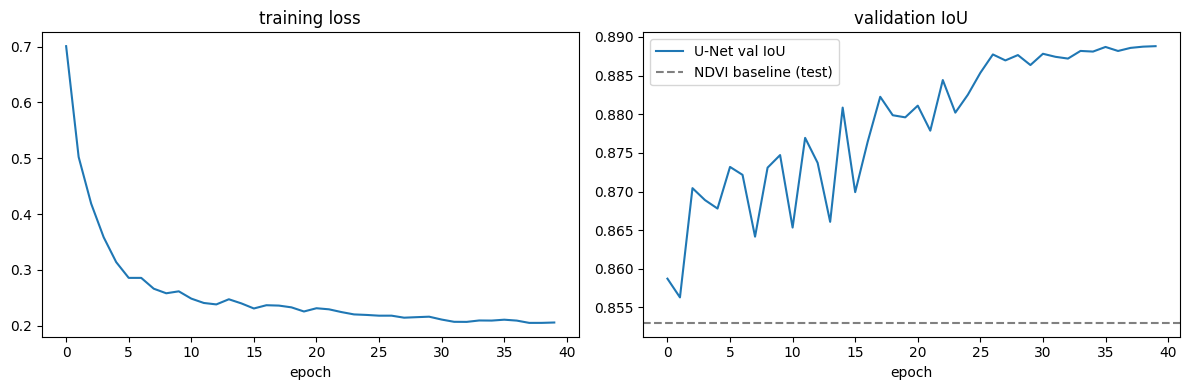

In [9]:
import matplotlib.pyplot as plt
h = history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([r["loss"] for r in h]); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot([r["iou"] for r in h], label="U-Net val IoU"); ax[1].axhline(0.853, ls="--", c="gray", label="NDVI baseline (test)")
ax[1].set_title("validation IoU"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=100); plt.show()

Cell 9: see what the model actually predicts

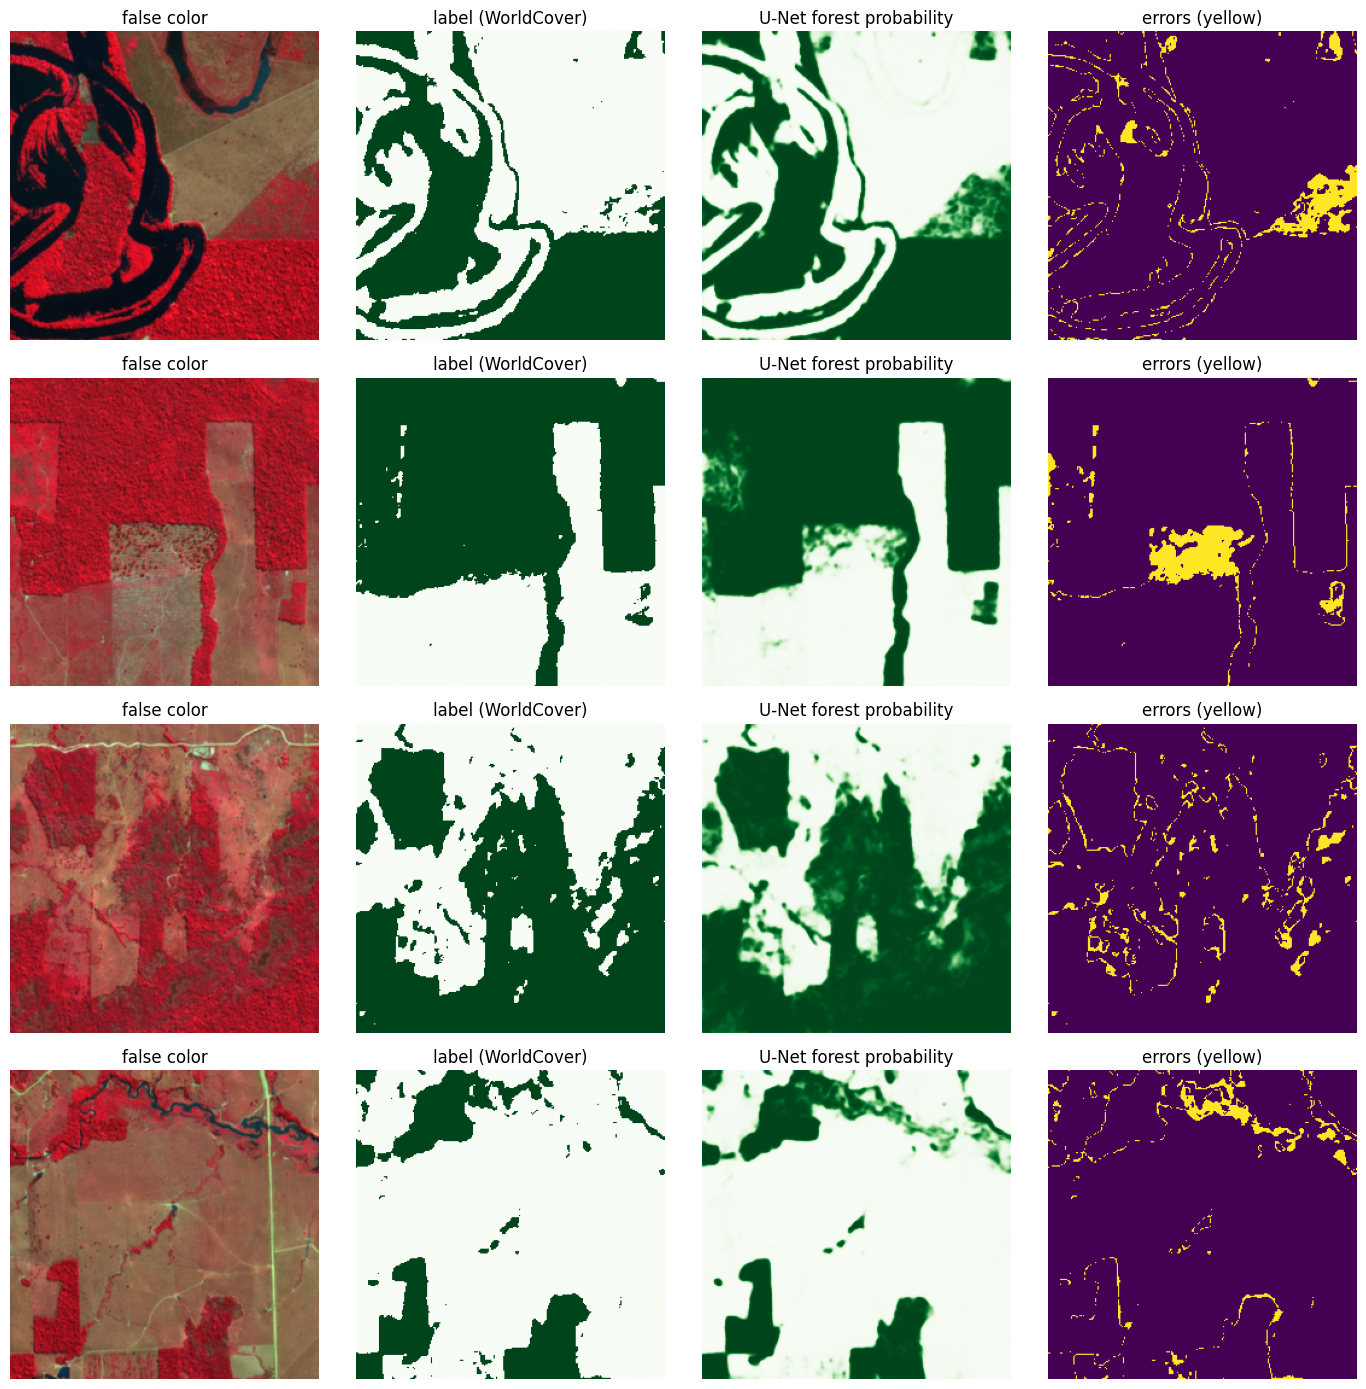

In [10]:
model.eval()
idx = np.linspace(0, len(feats["test"]) - 1, 4).astype(int)
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for row, i in enumerate(idx):
    raw = data["test"]["X"][i].astype("float32")
    false_color = np.clip(np.stack([raw[3] / 4500, raw[2] / 3000, raw[1] / 3000], -1), 0, 1)
    with torch.no_grad():
        prob = torch.sigmoid(model(torch.from_numpy(feats["test"][i:i + 1]).to(device))).cpu().numpy()[0]
    y = labels["test"][i]
    wrong = np.where(y == 255, np.nan, (prob > 0.5) != (y == 1))
    for a, img, title, cmap in zip(axes[row], [false_color, y == 1, prob, wrong],
                                   ["false color", "label (WorldCover)", "U-Net forest probability", "errors (yellow)"],
                                   [None, "Greens", "Greens", "viridis"]):
        a.imshow(img, cmap=cmap, vmin=0, vmax=1); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.savefig("test_predictions.png", dpi=90); plt.show()